# Stimulus-driven HMM — make the generated fish follow the dots

`fit_hmm.ipynb` fit a *spontaneous* 3-state HMM to the discretized bouts but ignored the visual stimulus. This notebook extends it to an **input-driven HMM** (IO-HMM / GLM-HMM) whose reorientation is biased toward the moving dots of the semi-closed-loop assay — capturing the *following* behavior described in the Perrino thesis (2026).

**Input.** Each bout carries the **egocentric bearing to the active dots**, `phi = stim_angle_rad` (angle of the active-dot centroid minus the fish's heading; **+ = dots on the fish's left**), measured at the bout onset. We turn it into a bounded signal `b = sin(phi)` (present & *moving* stimulus only, else 0), recomputed **each bout** during generation from the fish's current pose and the real dot positions — so the synthetic fish reacts as it swims.

**Sign-neutral states** (avoids any left/right label confusion — because `dtheta` and `phi` share the same world frame, turning *toward* the dots always means `sign(dtheta)=sign(phi)`):
- **0 = Forward**: `Normal(dtheta; mu_F, sigma)`, `mu_F = g·b`
- **1 = turn−**: `Gamma(−dtheta; alpha, theta)` on `dtheta<0`
- **2 = turn+**: `Gamma(+dtheta; alpha, theta)` on `dtheta>0`

**Input-driven transition** (this is where following lives):
$$\text{logit}\,p(j\mid i, b) = \log T_0[i,j] + \kappa\, c_j\, b,\qquad c=(0,-1,+1)$$
with `kappa ≥ 0` the learned **following gain**. Dots on the left (`b>0`) favour `turn+` (`dtheta>0`, CCW toward them); `b=0` recovers the spontaneous symmetric HMM.

**Optimiser (adapted Baum-Welch).** Same EM skeleton; the transition/emission are now functions of `b_n`, so the forward–backward uses a **time-varying** transition `T^(n)=T(b_n)`. In the M-step: the `b`-free parts (turn `Gamma`, forward `sigma`) keep their closed-form weighted-MLE updates; the forward-mean gain `g` is a weighted least-squares; and `T_0`+`kappa` (no closed form) are fit by a small **multinomial-logit / GLM-HMM step** (L-BFGS) on the `xi` transition responsibilities, binned by input `b`. All in `scripts/fit_hmm_stim.py`.

## 1. Sequences with the stimulus bearing — is there following in the data?

15 trajectories, 70771 bouts, 25731 stimulus-driven (moving dots)
P(turn toward dots | turning) = 0.623   (0.5 = no following)


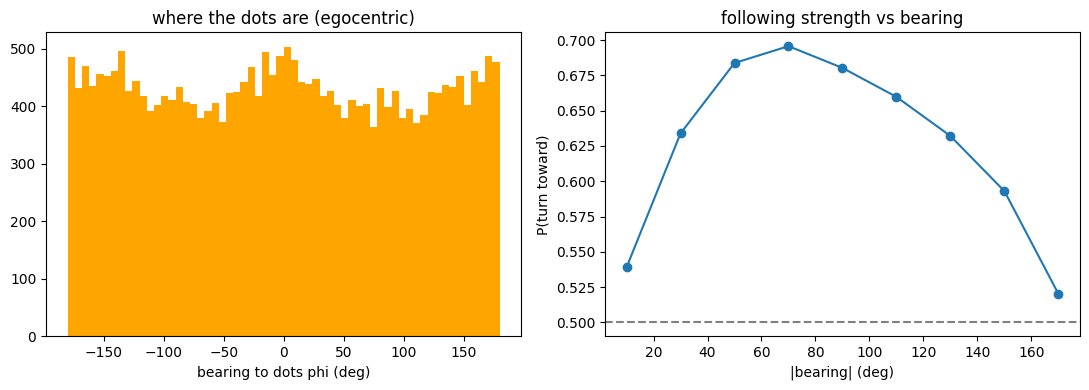

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm, gamma as gamma_dist

ROOT = Path.cwd()
if not (ROOT / "scripts").exists() and (ROOT.parent / "scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import fit_hmm_stim as S

df = pd.read_csv(ROOT / "data" / "bouts_GsizeMotionSingle.csv")
seqs = S.load_sequences_with_stim(df, min_len=10, require_moving=True)
n_bouts = sum(len(s[0]) for s in seqs)
n_drive = sum(int((s[1] != 0).sum()) for s in seqs)
print(f"{len(seqs)} trajectories, {n_bouts} bouts, {n_drive} stimulus-driven (moving dots)")

# Data check: during moving stimuli, do turns go TOWARD the dots?
m = df[df["moving"] == True].dropna(subset=["stim_angle_rad"])
phi = m["stim_angle_rad"].to_numpy(); dth = np.radians(m["dtheta_deg"].to_numpy())
turn = np.abs(np.degrees(dth)) > 10
toward = (np.sign(np.sin(phi[turn])) == np.sign(dth[turn])).mean()
print(f"P(turn toward dots | turning) = {toward:.3f}   (0.5 = no following)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.degrees(phi), bins=60, color="orange"); ax[0].set_xlabel("bearing to dots phi (deg)"); ax[0].set_title("where the dots are (egocentric)")
# turn-toward rate vs |bearing|
ab = np.abs(np.degrees(phi[turn])); sgn = (np.sign(np.sin(phi[turn])) == np.sign(dth[turn]))
bins = np.linspace(0, 180, 10); idx = np.digitize(ab, bins)
rate = [sgn[idx == i].mean() if (idx == i).sum() > 20 else np.nan for i in range(1, len(bins))]
ax[1].plot(0.5 * (bins[:-1] + bins[1:]), rate, "o-"); ax[1].axhline(0.5, color="gray", ls="--")
ax[1].set_xlabel("|bearing| (deg)"); ax[1].set_ylabel("P(turn toward)"); ax[1].set_title("following strength vs bearing")
plt.tight_layout(); plt.show()

## 2. Load the fitted model

This notebook defaults to the **rich** model (`data/hmm_stim_rich_GsizeMotionSingle.npz`), which describes the stimulus by per-dot **presence + motion** features (keeps group size, spread, distance, speed). `load_model_any` also reads the **simple** centroid-`sin(phi)` model (`data/hmm_stim_GsizeMotionSingle.npz`) — every cell below branches on `m["mode"]`.

Fit either from a shell:
```
uv run scripts/fit_hmm_stim.py fit            # rich  -> hmm_stim_rich_*.npz
uv run scripts/fit_hmm_stim.py fit --simple   # simple -> hmm_stim_*.npz
```
For the rich model, `beta_odd` (steer: which way) and `beta_even` (propensity: whether to turn) each split into a **prox** (presence, incl. static dots) and a **mot** (moving-dot bonus) channel.

In [ ]:
# RICH model by default (per-dot presence + motion features). For the simple
# centroid sin(phi) model instead, point MODEL_PATH at hmm_stim_GsizeMotionSingle.npz.
MODEL_PATH = ROOT / "data" / "hmm_stim_GsizeMotionSingle.npz"
m = S.load_model_any(MODEL_PATH)          # auto-detects simple vs rich (no KeyError)
print("model mode:", m["mode"])
if m["mode"] == "rich":
    print("beta_odd  [steer -> which way ]: L_prox=%+.3f  L_mot=%+.3f" % tuple(m["beta_odd"]))
    print("beta_even [propensity -> turn?]: S_prox=%+.3f  S_mot=%+.3f" % tuple(m["beta_even"]))
    print("  => steers toward NEAR dots (moving OR static); MOVING dots raise the turn rate")
else:
    print("kappa (following gain):", round(m["kappa"], 3))
print("g=%.3f  sigma=%.2f deg  alpha=%.2f  theta=%.2f deg" % (m["g"], m["sigma"], m["alpha"], m["theta"]))
print("T0 (no stimulus, rows F/turn-/turn+):\n", np.round(S.T0_matrix_g(m), 3))

model mode: rich
beta_odd  [steer -> which way ]: L_prox=+0.129  L_mot=+0.011
beta_even [propensity -> turn?]: S_prox=-0.026  S_mot=+0.043
  => steers toward NEAR dots (moving OR static); MOVING dots raise the turn rate
g=-0.824  sigma=6.44 deg  alpha=2.33  theta=21.19 deg
T0 (no stimulus, rows F/turn-/turn+):
 [[0.194 0.403 0.403]
 [0.073 0.494 0.434]
 [0.073 0.434 0.494]]


## 3. What the model learned: the following bias + emissions

Left: how the turn split tilts with the stimulus bearing `b` (the `kappa` effect). Right: fitted emissions vs the data histogram (unchanged spontaneous shape).

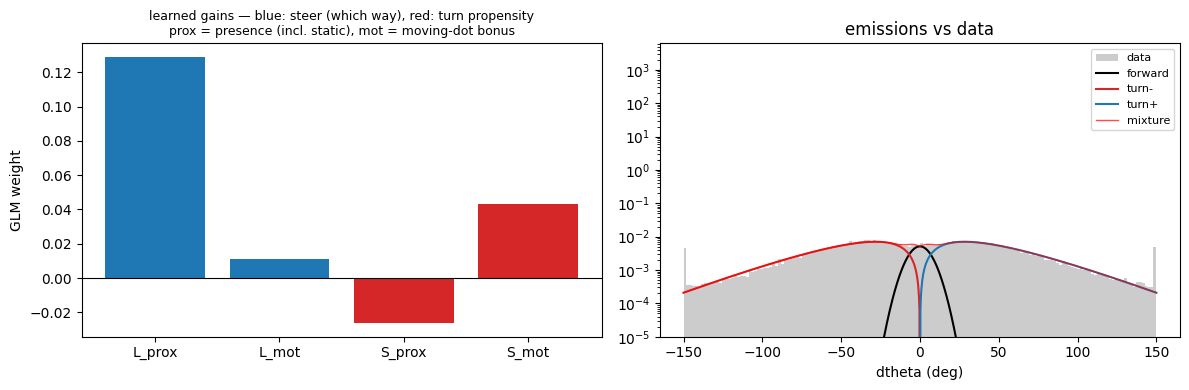

In [3]:
alld = np.concatenate([s[0] for s in seqs])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# LEFT: what the model learned about following
if m["mode"] == "rich":
    labels = ["L_prox", "L_mot", "S_prox", "S_mot"]
    vals = np.r_[m["beta_odd"], m["beta_even"]]
    ax[0].bar(range(4), vals, color=["C0", "C0", "C3", "C3"])
    ax[0].set_xticks(range(4), labels); ax[0].axhline(0, color="k", lw=.8)
    ax[0].set_ylabel("GLM weight")
    ax[0].set_title("learned gains — blue: steer (which way), red: turn propensity\n"
                    "prox = presence (incl. static), mot = moving-dot bonus", fontsize=9)
else:
    bb = np.linspace(-1, 1, 101); L0 = S._L0_from_params(m["u"])
    ax[0].plot(bb, [S.trans_matrix(L0, m["kappa"], b)[1, 2] for b in bb], "C0", label="P(turn+)")
    ax[0].plot(bb, [S.trans_matrix(L0, m["kappa"], b)[1, 1] for b in bb], "C3", label="P(turn-)")
    ax[0].axvline(0, color="gray", ls="--"); ax[0].set_xlabel("b = sin(phi)")
    ax[0].set_ylabel("transition prob"); ax[0].legend(fontsize=8)
    ax[0].set_title(f"following bias (kappa={m['kappa']:.2f})")

# RIGHT: fitted emissions vs the data histogram (same for both modes)
w = S.H.steady_state(S.T0_matrix_g(m)); xg = np.linspace(-150, 150, 1001)
pf = w[0] * norm.pdf(xg, 0, m["sigma"])
pl = np.where(xg < 0, w[1] * gamma_dist.pdf(-xg, m["alpha"], scale=m["theta"]), 0)
pr = np.where(xg > 0, w[2] * gamma_dist.pdf(xg, m["alpha"], scale=m["theta"]), 0)
ax[1].hist(np.clip(alld, -150, 150), bins=160, density=True, color="0.8", label="data")
ax[1].plot(xg, pf, "k", lw=1.5, label="forward"); ax[1].plot(xg, pl, "C3", lw=1.5, label="turn-")
ax[1].plot(xg, pr, "C0", lw=1.5, label="turn+"); ax[1].plot(xg, pf+pl+pr, "r", lw=1, alpha=.7, label="mixture")
ax[1].set_xlabel("dtheta (deg)"); ax[1].set_yscale("log"); ax[1].set_ylim(1e-5, None)
ax[1].legend(fontsize=8); ax[1].set_title("emissions vs data")
plt.tight_layout(); plt.show()

## 4. Controlled demo: does the generated fish steer toward a stimulus?

Place a virtual stimulus at a fixed world point and roll the model out bout-by-bout, recomputing the bearing `phi` from the synthetic pose each bout. Compare the fitted `kappa` (following) against `kappa=0` (spontaneous): with following, the path bends toward the dot.

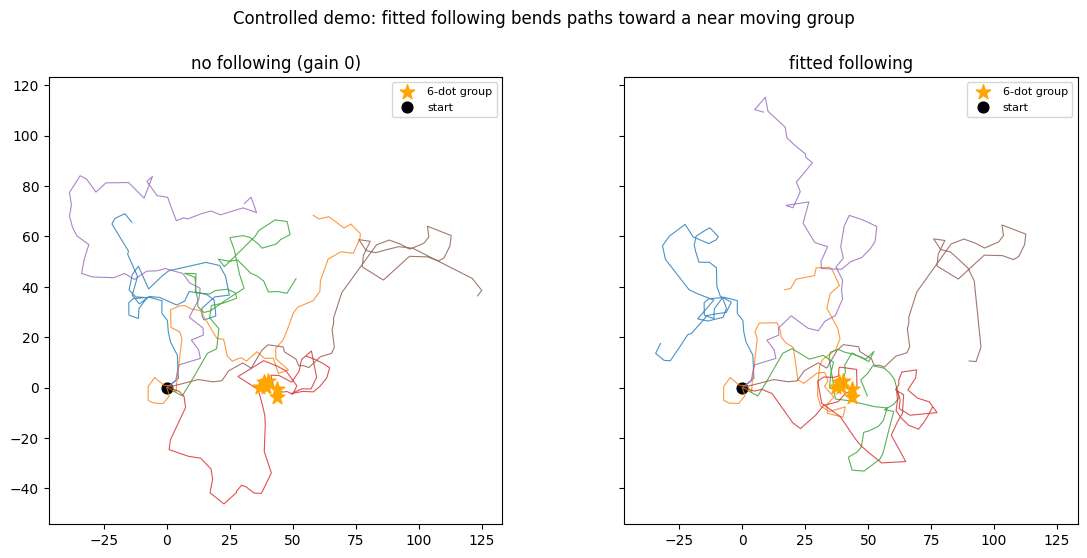

gain 0  : time within 30 mm of the group = 0.249
fitted  : time within 30 mm of the group = 0.393


In [4]:
# Controlled demo: a CLUSTER of moving dots (like a real group) at a fixed world
# point; roll the model out bout-by-bout, recomputing the stimulus features from
# the synthetic pose each bout. (A single far dot barely drives the rich model --
# by design it down-weights lone/distant dots; following emerges from groups.)
dist_pool = df["distance_px"].dropna().to_numpy()

def make_group(center, n_dots=6, spread=4.0, seed=1):
    rng = np.random.default_rng(seed)
    return (center[0] + rng.uniform(-spread, spread, n_dots),
            center[1] + rng.uniform(-spread, spread, n_dots))

def steer_prop(model, fx, fy, fori, gx, gy, v_stim=3.5):
    k = min(len(gx), 8)
    dx = np.zeros(8); dy = np.zeros(8); act = np.zeros(8, bool)
    dxp = dx.copy(); dyp = dy.copy(); actp = act.copy()
    act[:k] = actp[:k] = True; dx[:k] = gx[:k]; dy[:k] = gy[:k]
    dxp[:k] = dx[:k] - v_stim / 30.0; dyp[:k] = dy[:k]         # moving dots
    if model["mode"] == "rich":
        U = S._covariates(fx, fy, fori, dx, dy, act, dxp, dyp, actp, s_f=S.S_F) / model["scales"]
        return float(U[0:2] @ model["beta_odd"]), float(U[2:4] @ model["beta_even"])
    phi = (np.arctan2(np.mean(gy) - fy, np.mean(gx) - fx) - fori + np.pi) % (2 * np.pi) - np.pi
    return model["kappa"] * np.sin(phi), 0.0

def rollout(model, gain, gx, gy, n=50, seed=0):
    rng = np.random.default_rng(seed); L0 = S._L0_from_params(model["u"])
    x = y = ori = 0.0; state = 0; xs, ys = [x], [y]
    for _ in range(n):
        st, pr = steer_prop(model, x, y, ori, gx, gy); st *= gain; pr *= gain
        T = S._trans_scalars(L0, st, pr); state = int(rng.choice(3, p=T[state]))
        if state == 0:
            dth = rng.normal(model["g"] * st, model["sigma"])
        else:
            mag = rng.gamma(model["alpha"], model["theta"]); dth = -mag if state == 1 else mag
        ori += np.radians(dth); step = float(rng.choice(dist_pool))
        x += step * np.cos(ori); y += step * np.sin(ori); xs.append(x); ys.append(y)
    return np.array(xs), np.array(ys)

gx, gy = make_group((40.0, 0.0), n_dots=6, spread=4.0)     # 6-dot moving group to the right
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for a, gain, name in [(ax[0], 0.0, "no following (gain 0)"), (ax[1], 1.0, "fitted following")]:
    for s in range(6):
        xs, ys = rollout(m, gain, gx, gy, 50, s)
        a.plot(xs, ys, lw=0.8, alpha=0.8)
    a.scatter(gx, gy, marker="*", s=120, color="orange", zorder=5, label="6-dot group")
    a.scatter(0, 0, marker="o", s=60, color="k", label="start")
    a.set_aspect("equal"); a.set_title(name); a.legend(fontsize=8)
plt.suptitle("Controlled demo: fitted following bends paths toward a near moving group", y=1.0)
plt.tight_layout(); plt.show()

# quantify: fraction of time within 30 mm of the group centre
gc = (np.mean(gx), np.mean(gy))
for gain, nm in [(0.0, "gain 0"), (1.0, "fitted")]:
    fr = np.mean([np.mean(np.hypot(*[a - b for a, b in zip(rollout(m, gain, gx, gy, 60, s), gc)]) < 30)
                  for s in range(30)])
    print(f"{nm:8s}: time within 30 mm of the group = {fr:.3f}")

## 5. Comparison video (real vs stimulus-driven HMM)

The sampler writes per-frame trajectory CSVs in the **df_base schema** that the **existing, unmodified** `scripts/visualize.py` renders into the 2×N comparison video — same stimulus on top (real) and bottom (HMM), so you can see whether the model reproduces the reaction to the dots. Between bouts the fish holds still and darts at each bout onset (bout-level model at 30 fps).

The cell below does the whole thing **from the notebook** (no repo `.py` is modified): it (1) generates the trial CSVs with `S.generate_trials(...)`, (2) points matplotlib at the bundled `imageio-ffmpeg` binary, and (3) calls `visualize.main()` to write `runs/hmm_stim/comparison.mp4`. The equivalent shell workflow is:

```
uv run scripts/fit_hmm_stim.py video --output runs/hmm_stim/samples --n 4
uv run scripts/visualize.py --samples runs/hmm_stim/samples --output runs/hmm_stim/comparison.mp4 --n 4
```

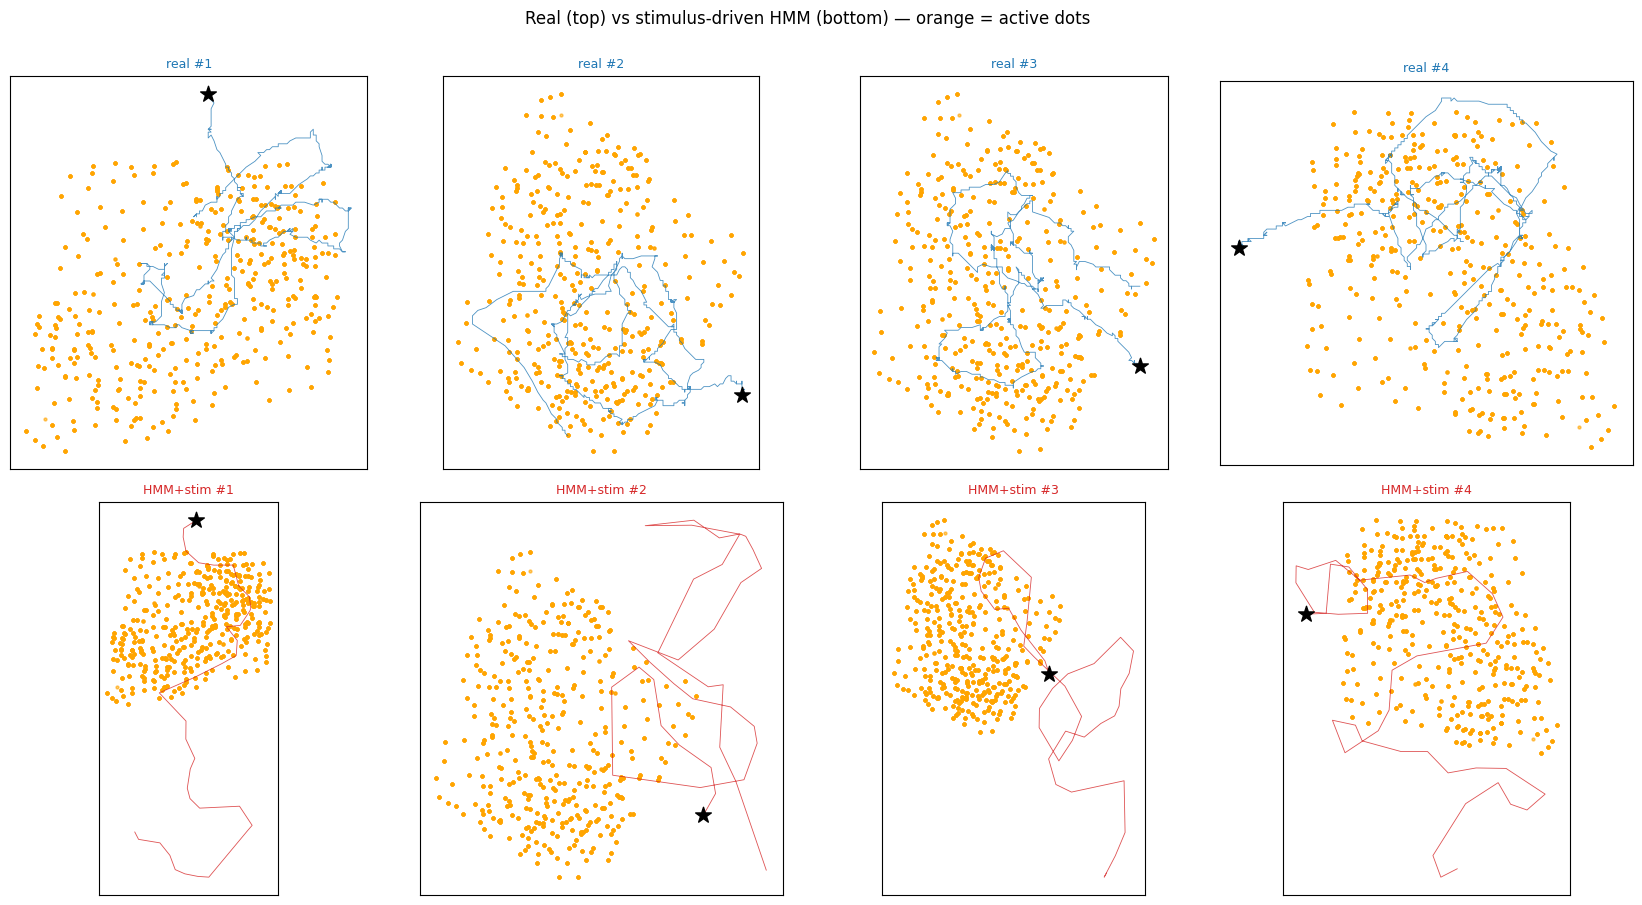

In [5]:
samples = ROOT / "runs" / "hmm_stim" / "samples"
if not samples.exists() or not list(samples.glob("trial_*.csv")):
    print("No trials yet — run the `video` CLI above first.")
else:
    trials = sorted(p for p in samples.glob("trial_*.csv") if "_real" not in p.name)[:4]
    fig, axes = plt.subplots(2, len(trials), figsize=(4.2 * len(trials), 9))
    for col, tp in enumerate(trials):
        real = pd.read_csv(str(tp).replace(".csv", "_real.csv")); syn = pd.read_csv(tp)
        for r, (d, name, c) in enumerate([(real, "real", "C0"), (syn, "HMM+stim", "C3")]):
            ax = axes[r, col]
            ax.plot(d["f_x"], d["f_y"], lw=0.6, color=c, alpha=0.8)
            ax.scatter(d["f_x"].iloc[0], d["f_y"].iloc[0], marker="*", s=140, color="k", zorder=5)
            dx, dy = [], []
            for k in range(8):
                mm2 = d[f"d{k}_stim"].astype(bool)
                dx += list(d.loc[mm2, f"d{k}_x"]); dy += list(d.loc[mm2, f"d{k}_y"])
            ax.scatter(dx, dy, s=4, color="orange", alpha=0.25, zorder=1)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{name} #{col+1}", color=c, fontsize=9)
    plt.suptitle("Real (top) vs stimulus-driven HMM (bottom) — orange = active dots", y=1.0)
    plt.tight_layout(); plt.show()

In [ ]:
import pickle, subprocess

# ---- 1. generate the trial CSVs (df_base schema) from the fitted model ----
samples = ROOT / "runs" / "hmm_stim" / "samples"
with open(ROOT / "notebooks" / "abs_dict.pkl", "rb") as f:
    abs_dict = pickle.load(f)
roi = pd.read_csv(ROOT / "data" / "data" / "ROIdef.csv", header=None,
                  names=["xoff", "yoff", "diameter", "x", "y", "radius"])
gen = S.generate_trials_rich if m.get("mode") == "rich" else S.generate_trials
n_made = gen(m, abs_dict, roi, df, samples, n=4, seed=0)
print(f"generated {n_made} trials ({m.get('mode','simple')} model) in {samples}")

# ---- 2. render the mp4 in a SUBPROCESS (isolated) with the UNMODIFIED visualize.py ----
# Running the heavy 1709-frame animation inside the notebook kernel can crash it
# (memory). A subprocess renders it safely; we only set the bundled ffmpeg path.
mp4_path = ROOT / "runs" / "hmm_stim" / "comparison_simpleHMM.mp4"
code = (
    "import sys, imageio_ffmpeg, matplotlib as mpl;"
    "mpl.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe();"
    f"sys.path.insert(0, r'{ROOT / 'scripts'}');"
    f"sys.argv = ['visualize.py','--samples', r'{samples}','--output', r'{mp4_path}',"
    f"'--n','{n_made}','--speed','3'];"
    "import visualize; visualize.main()"
)
subprocess.run([sys.executable, "-c", code], check=True)
print("saved", mp4_path, "-> open in any video player (VLC / browser)")

  fish 0 frames 1440:3240 -> trial_000 (1709 frames, 2.52 px/mm)
  fish 1 frames 1440:3240 -> trial_001 (1709 frames, 3.16 px/mm)
  fish 2 frames 1440:3240 -> trial_002 (1709 frames, 3.29 px/mm)
  fish 3 frames 1440:3240 -> trial_003 (1709 frames, 2.83 px/mm)
generated 4 trials (rich model) in c:\Users\arthu\mp_semiCL_behavior\runs\hmm_stim\samples
saved c:\Users\arthu\mp_semiCL_behavior\runs\hmm_stim\comparison.mp4 -> open in any video player (VLC / browser)


## 6. How the optimiser was adapted, and notes

**Adapting Baum-Welch for the stimulus parameter** (in `fit_io_hmm`):
- **E-step** — the forward–backward now indexes a *time-varying* transition `T^(n)=T(b_n)` (`_build_T_seq`) and an input-shifted forward emission; `alpha/beta/gamma/xi` recursions are otherwise identical to the spontaneous fit.
- **M-step** —
  - turn `Gamma(alpha,theta)`: same weighted MLE as `fit_hmm.py` (pool `|dtheta|` over turn states) — independent of `b`.
  - forward mean `g`, `sigma`: weighted least-squares through the origin (`mu_F = g·b`) + weighted variance.
  - `T0` + `kappa`: **no closed form** → maximise the expected complete-data log-likelihood `Σ xi·log p(j|i;b)` with L-BFGS (`_fit_transition`). The `xi` responsibilities are **binned by input `b`** (~40 bins) so the GLM step is cheap. This is the standard GLM-HMM / IO-HMM M-step.

**Results.** `kappa` came out **> 0** — the fish turns toward the dots — matching the raw-data statistic (P(turn toward) ≈ 0.62 during moving stimuli). The spontaneous parameters (`sigma≈6.5`, `alpha≈2.3`, `theta≈21`, `T0`) match `fit_hmm.py`, so the stimulus term is a clean addition, not a re-fit of the base behavior.

**Caveats / next steps.**
- The bias signal is `b = sin(phi)`; you could instead use the raw `phi/pi`, add a salience gate on dot number/speed, or make `kappa` depend on distance to the dots. `--include-static` lets static-dot bouts also drive following (off by default; the thesis reports static dots don't sustain attraction).
- Generation resamples `dt`/`distance` from the global empirical pools (paper convention); turn magnitude is not yet stimulus-modulated (only turn *direction* is). If you want the fish to also take *bigger* steps toward salient groups, make `theta` or the step distance scale with salience.
- **Video**: the `.mp4` is produced by the **unmodified** `scripts/visualize.py`; we only set `matplotlib.rcParams["animation.ffmpeg_path"]` to the `imageio-ffmpeg` binary in the calling process (installed once with `uv pip install imageio-ffmpeg`). No original repo file is changed. A system `ffmpeg` on PATH would also work.